In [ ]:
from collections import deque
from graphviz import Digraph

def vacuum_actions(state):
    position, A, B = state
    actions = []

    # Clean the room currently occupied
    if position == "A" and A == 1:
        actions.append(("SUCK", ("A", 0, B)))

    if position == "B" and B == 1:
        actions.append(("SUCK", ("B", A, 0)))

    # Move between rooms
    if position == "A":
        actions.append(("RIGHT", ("B", A, B)))
    else:
        actions.append(("LEFT", ("A", A, B)))

    return actions

def is_goal(state):
    return state[1] == 0 and state[2] == 0

In [ ]:
from itertools import product

states = list(product(["A", "B"], [0, 1], [0, 1]))

for i, state in enumerate(states, start=1):
    position, A, B = state
    print(
        f"State {i}: Vacuum={position}, "
        f"A={'Dirty' if A else 'Clean'}, "
        f"B={'Dirty' if B else 'Clean'}"
    )

print("\nTotal states:", len(states))

State 1: Vacuum=A, A=Clean, B=Clean
State 2: Vacuum=A, A=Clean, B=Dirty
State 3: Vacuum=A, A=Dirty, B=Clean
State 4: Vacuum=A, A=Dirty, B=Dirty
State 5: Vacuum=B, A=Clean, B=Clean
State 6: Vacuum=B, A=Clean, B=Dirty
State 7: Vacuum=B, A=Dirty, B=Clean
State 8: Vacuum=B, A=Dirty, B=Dirty

Total states: 8


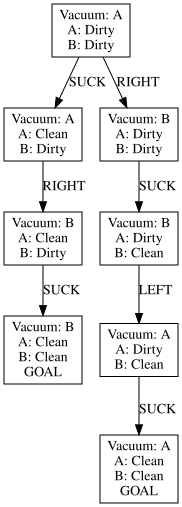

In [ ]:
def vacuum_tree(initial_state):
    tree = Digraph()
    tree.attr(rankdir="TB")
    tree.attr("node", shape="box")

    visited = set()
    queue = deque([(initial_state, None, None)])

    while queue:
        state, parent_id, action = queue.popleft()

        if state in visited:
            continue

        visited.add(state)
        node_id = str(len(visited))

        position, A, B = state
        label = (
            f"Vacuum: {position}\n"
            f"A: {'Dirty' if A else 'Clean'}\n"
            f"B: {'Dirty' if B else 'Clean'}"
        )

        if is_goal(state):
            label += "\nGOAL"

        tree.node(node_id, label)

        if parent_id is not None:
            tree.edge(parent_id, node_id, label=action)

        if is_goal(state):
            continue

        for action, next_state in vacuum_actions(state):
            if next_state not in visited:
                queue.append((next_state, node_id, action))

    return tree

initial_state = ("A", 1, 1)
vacuum_tree(initial_state)

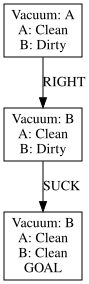

In [ ]:
initial_state = ("A", 0, 1)
vacuum_tree(initial_state)